# Gold layer analysis (Data Scientist)

In [1]:
from pyspark.sql import SparkSession
spark = (SparkSession.builder.appName("analysis")
    .config("spark.hadoop.fs.defaultFS", "hdfs://namenode:9000")
    .config("spark.hadoop.hive.metastore.uris", "thrift://hive-metastore:9083")
    .enableHiveSupport().getOrCreate())
spark.sql("SHOW DATABASES").show()

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/11/20 05:07:45 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


+---------+
|namespace|
+---------+
|   bronze|
|  default|
|     gold|
|   silver|
+---------+



In [2]:
spark.sql("SELECT * FROM gold.category_sales ORDER BY total_amount DESC").show()

+-----------+------------+-------------+-------------+-------------------+--------------------+
|   category|total_amount|invoice_count|average_price|    last_invoice_ts|          updated_at|
+-----------+------------+-------------+-------------+-------------------+--------------------+
|      Books|   134898.79|          278|       485.25|2026-11-20 04:52:21|2026-11-20 04:53:...|
|  Furniture|   128298.05|          241|       532.36|2026-11-20 04:52:35|2026-11-20 04:53:...|
|   Clothing|   127425.17|          255|       499.71|2026-11-20 04:52:09|2026-11-20 04:53:...|
|       Food|   117239.99|          241|       486.47|2026-11-20 04:52:33|2026-11-20 04:53:...|
|Electronics|   111528.43|          217|       513.96|2026-11-20 04:52:27|2026-11-20 04:53:...|
+-----------+------------+-------------+-------------+-------------------+--------------------+



<Axes: title={'center': 'Total sales per category'}, xlabel='category'>

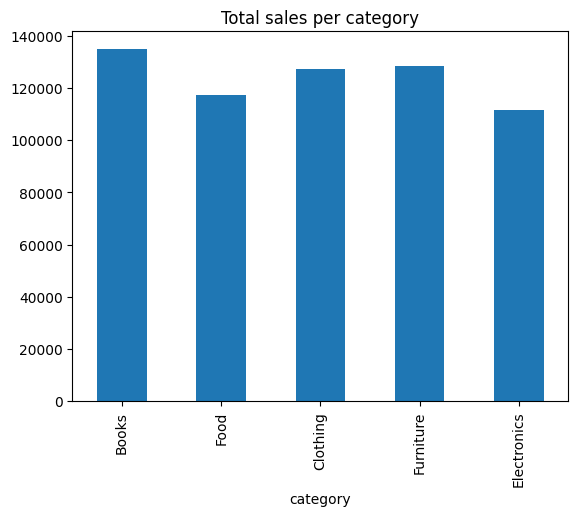

In [3]:
pdf = spark.table("gold.category_sales").toPandas()
pdf.plot(kind="bar", x="category", y="total_amount", legend=False, title="Total sales per category")

In [4]:
# Silver: average price per hour
spark.sql("""SELECT date_trunc('hour', invoice_ts) AS hour, category, ROUND(AVG(price),2) AS avg_price
             FROM silver.invoices_clean GROUP BY 1,2 ORDER BY 1,2""").show(50)

[Stage 2:>                                                          (0 + 8) / 8]

+-------------------+-----------+---------+
|               hour|   category|avg_price|
+-------------------+-----------+---------+
|2026-11-20 04:00:00|      Books|   485.25|
|2026-11-20 04:00:00|   Clothing|   499.71|
|2026-11-20 04:00:00|Electronics|   513.96|
|2026-11-20 04:00:00|       Food|   486.47|
|2026-11-20 04:00:00|  Furniture|   532.36|
+-------------------+-----------+---------+

